# LAB — Bagging e Boosting com o dataset Iris

**Disciplina:** Inteligência Artificial — Machine Learning  
**Alunos:** Patrick Barreira (RA00334687) e Nicolas Mariano (RA00333111)

**Objetivo:** implementar dois métodos de ensemble com scikit-learn e comparar seu desempenho na classificação das espécies de flores Iris. O dataset é carregado pelo pacote `vega_datasets`, conforme solicitado no LAB.

> **Antes da entrega:** confirmar com a turma que nenhum outro grupo escolheu o dataset Iris. A publicação no GitHub e o envio do link no Teams serão feitos depois.

## 1. Método

- **Bagging:** treina várias árvores de decisão em amostras bootstrap e combina suas previsões por votação.
- **Boosting:** treina árvores sequencialmente, com cada etapa melhorando o modelo anterior por meio da otimização da função de perda.

Usaremos a mesma divisão estratificada para os dois modelos. O conjunto de teste fica reservado exclusivamente para a avaliação final. Como os dois métodos são baseados em árvores e as quatro variáveis já são numéricas, não é necessário padronizá-las.

In [1]:
# No Google Colab, instala o pacote do Vega somente se ele ainda não estiver disponível.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("vega_datasets") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "vega_datasets==0.9.0"])

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from vega_datasets import data
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

SEMENTE = 42

## 2. Dados e inspeção

Cada linha representa uma flor. As entradas são comprimento e largura da pétala e da sépala; a saída é a espécie (`species`). Verificamos o tamanho, as classes e valores ausentes antes de treinar.

In [2]:
df = data.iris()
atributos = ["petalLength", "petalWidth", "sepalLength", "sepalWidth"]
alvo = "species"

print(f"Dimensões: {df.shape[0]} linhas × {df.shape[1]} colunas")
display(df.head())
print("Distribuição das espécies:")
display(df[alvo].value_counts().sort_index().rename("quantidade"))
print("Valores ausentes por coluna:")
display(df[atributos + [alvo]].isna().sum().rename("ausentes"))

assert not df[atributos + [alvo]].isna().any().any(), "O dataset contém valores ausentes."

Dimensões: 150 linhas × 5 colunas


,sepalLength,sepalWidth,petalLength,petalWidth,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Distribuição das espécies:


species
setosa        50
versicolor    50
virginica     50
Name: quantidade, dtype: int64

Valores ausentes por coluna:


petalLength    0
petalWidth     0
sepalLength    0
sepalWidth     0
species        0
Name: ausentes, dtype: int64

## 3. Separação entre treino e teste

Separamos 75% das amostras para treino e 25% para teste. `stratify=y` preserva aproximadamente a proporção das três espécies em ambas as partes. A semente fixa permite reproduzir a divisão.

In [3]:
X = df[atributos]
y = df[alvo]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE
)

print(f"Amostras de treino: {len(X_treino)}")
print(f"Amostras de teste: {len(X_teste)}")
display(
    pd.DataFrame({
        "treino": y_treino.value_counts().sort_index(),
        "teste": y_teste.value_counts().sort_index(),
    })
)

Amostras de treino: 112
Amostras de teste: 38


,treino,teste
species,,
setosa,38,12
versicolor,37,13
virginica,37,13


## 4. Treinamento dos modelos

O Bagging usa 100 árvores de decisão limitadas a três níveis, com amostragem bootstrap. O Boosting usa 100 etapas, taxa de aprendizado de 0,1 e árvores de até três níveis. Esses parâmetros são definidos antes de examinar o teste; não fazemos ajuste de hiperparâmetros com os dados de teste.

In [4]:
modelos = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=3, random_state=SEMENTE),
        n_estimators=100,
        max_samples=1.0,
        bootstrap=True,
        n_jobs=1,
        random_state=SEMENTE,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=SEMENTE,
    ),
}

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    print(f"{nome}: treinamento concluído")

Bagging: treinamento concluído


Gradient Boosting: treinamento concluído


## 5. Avaliação e comparação

A **acurácia** mede a proporção total de acertos. O **F1 macro** calcula o F1 de cada espécie e tira a média sem privilegiar classes maiores. Os relatórios detalham precisão, revocação e F1 por espécie; as matrizes de confusão mostram quais classes foram confundidas.

In [5]:
previsoes = {}
resultados = []
classes = sorted(y.unique())

for nome, modelo in modelos.items():
    y_previsto = modelo.predict(X_teste)
    previsoes[nome] = y_previsto
    resultados.append({
        "modelo": nome,
        "acurácia": accuracy_score(y_teste, y_previsto),
        "F1 macro": f1_score(y_teste, y_previsto, average="macro"),
    })

tabela_resultados = pd.DataFrame(resultados).set_index("modelo")
display(tabela_resultados.round(3))

for nome, y_previsto in previsoes.items():
    print(f"\nRelatório de classificação — {nome}")
    print(classification_report(y_teste, y_previsto, labels=classes, zero_division=0))

,acurácia,F1 macro
modelo,,
Bagging,0.947,0.949
Gradient Boosting,0.974,0.974



Relatório de classificação — Bagging


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.92      0.92      0.92        13
   virginica       0.92      0.92      0.92        13

    accuracy                           0.95        38
   macro avg       0.95      0.95      0.95        38
weighted avg       0.95      0.95      0.95        38


Relatório de classificação — Gradient Boosting
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       1.00      0.92      0.96        13
   virginica       0.93      1.00      0.96        13

    accuracy                           0.97        38
   macro avg       0.98      0.97      0.97        38
weighted avg       0.98      0.97      0.97        38



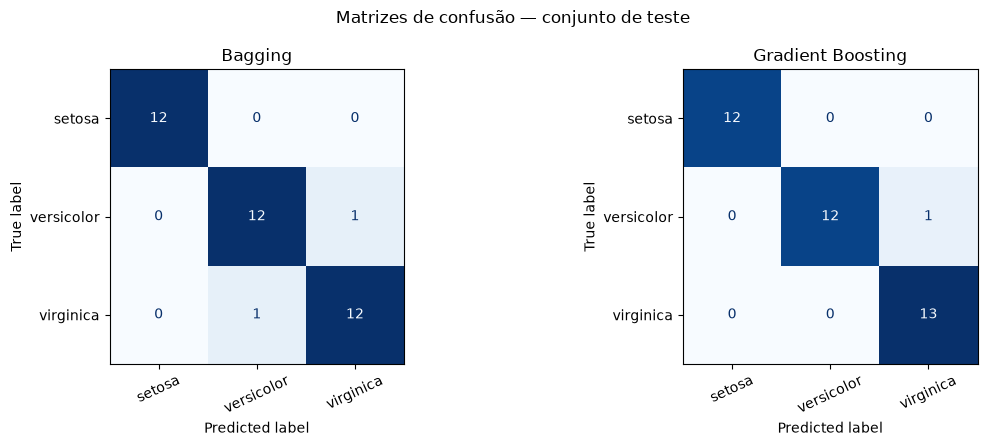

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

for eixo, (nome, y_previsto) in zip(eixos, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_teste,
        y_previsto,
        labels=classes,
        display_labels=classes,
        cmap="Blues",
        colorbar=False,
        ax=eixo,
    )
    eixo.set_title(nome)
    eixo.tick_params(axis="x", rotation=25)

fig.suptitle("Matrizes de confusão — conjunto de teste")
fig.tight_layout()
plt.show()

## 6. Interpretação dos resultados

O texto abaixo usa as métricas calculadas nesta execução. Uma diferença pequena entre os modelos em apenas uma divisão de teste não demonstra superioridade geral; o Iris é um conjunto pequeno e relativamente simples. Para uma análise mais robusta, seria possível repetir a comparação por validação cruzada, preservando o teste para avaliação final.

In [7]:
bagging = tabela_resultados.loc["Bagging"]
boosting = tabela_resultados.loc["Gradient Boosting"]
diferenca = bagging["F1 macro"] - boosting["F1 macro"]

print(
    f"No conjunto de teste, o Bagging obteve acurácia de {bagging['acurácia']:.3f} "
    f"e F1 macro de {bagging['F1 macro']:.3f}. "
    f"O Gradient Boosting obteve acurácia de {boosting['acurácia']:.3f} "
    f"e F1 macro de {boosting['F1 macro']:.3f}."
)

if abs(diferenca) < 1e-12:
    print("Os dois modelos empataram em F1 macro nesta divisão de teste.")
else:
    melhor = "Bagging" if diferenca > 0 else "Gradient Boosting"
    print(f"O {melhor} teve F1 macro maior nesta divisão por {abs(diferenca):.3f}.")

print(
    "Esta comparação vale para esta divisão e esta configuração dos modelos; "
    "não garante o mesmo resultado em outros dados."
)

No conjunto de teste, o Bagging obteve acurácia de 0.947 e F1 macro de 0.949. O Gradient Boosting obteve acurácia de 0.974 e F1 macro de 0.974.
O Gradient Boosting teve F1 macro maior nesta divisão por 0.026.
Esta comparação vale para esta divisão e esta configuração dos modelos; não garante o mesmo resultado em outros dados.


## Referências

- [Vega Datasets — pacote Python e dataset Iris](https://github.com/altair-viz/vega_datasets)
- [scikit-learn — métodos ensemble](https://scikit-learn.org/stable/modules/ensemble.html)
- [scikit-learn — BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)
- [scikit-learn — GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html)